<a href="https://colab.research.google.com/github/AndresMontesDeOca/vision_computadora_II/blob/VpC2_2026/TP/00_Notebook.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# 1. Configuración de Librerías e Instalación
Aquí instalamos y cargamos todas las bibliotecas de Python necesarias para trabajar con detección de objetos, visualización y descarga de datos.

In [8]:
# Instalación de dependencias indispensables
!pip install -q roboflow opencv-python matplotlib pyyaml

In [9]:
import os
import yaml
import json
import random
import cv2
import matplotlib.pyplot as plt
from google.colab import userdata
from roboflow import Roboflow

# 2. Carga del Dataset (Data Load)
En esta sección nos conectamos con la API de Roboflow para descargar la versión correspondiente de nuestro dataset de Counter-Strike y cargamos su configuración `data.yaml`.

In [10]:
# Obtener la clave API de Roboflow de los secretos de Colab de manera segura
api_key = userdata.get("ROBOFLOW_API_KEY")
rf = Roboflow(api_key=api_key)

# Descarga del dataset en formato YOLOv11
project = rf.workspace("counter-strike-uovxc").project("counter-strike-h9y80")
version = project.version(1)
dataset = version.download("yolov11")

loading Roboflow workspace...
loading Roboflow project...


In [11]:
# Cargar y mostrar la configuración de clases y rutas
with open('/content/Counter-Strike-1/data.yaml', 'r') as file:
    dataset_info = yaml.safe_load(file)

print("Estructura y clases del dataset:")
print(json.dumps(dataset_info, indent=4))

Estructura y clases del dataset:
{
    "train": "../train/images",
    "val": "../valid/images",
    "test": "../test/images",
    "nc": 2,
    "names": [
        "ct",
        "t"
    ],
    "roboflow": {
        "workspace": "counter-strike-uovxc",
        "project": "counter-strike-h9y80",
        "version": 1,
        "license": "CC BY 4.0",
        "url": "https://universe.roboflow.com/counter-strike-uovxc/counter-strike-h9y80/dataset/1"
    }
}


# 3. Funciones Auxiliares
Definimos las funciones encargadas de interpretar el formato YOLO (coordenadas normalizadas) y plasmar visualmente las cajas delimitadoras sobre las imágenes originales.

In [12]:
def plot_yolo_sample(img_path, lbl_path, class_names):
    """Dibuja cajas YOLO en una imagen usando azul para CT y rojo para Terroristas."""
    if not os.path.exists(img_path):
        print(f"No se encontró la imagen: {img_path}")
        return

    # Cargar y convertir imagen
    image = cv2.imread(img_path)
    image = cv2.cvtColor(image, cv2.COLOR_BGR2RGB)
    h, w, _ = image.shape

    # Colores en RGB: Azul para clase 0 (ct), Rojo para clase 1 (t)
    colors = [(0, 0, 255), (255, 0, 0)]

    if os.path.exists(lbl_path):
        with open(lbl_path, 'r') as f:
            lines = f.readlines()

        for line in lines:
            parts = line.strip().split()
            if len(parts) == 5:
                cls_id = int(parts[0])
                x_center, y_center, bbox_w, bbox_h = map(float, parts[1:])

                # Convertir coordenadas YOLO normalizadas a píxeles
                x1 = int((x_center - bbox_w / 2) * w)
                y1 = int((y_center - bbox_h / 2) * h)
                x2 = int((x_center + bbox_w / 2) * w)
                y2 = int((y_center + bbox_h / 2) * h)

                # Dibujar rectángulo y texto informativo
                color = colors[cls_id % len(colors)]
                cv2.rectangle(image, (x1, y1), (x2, y2), color, 2)

                label = class_names[cls_id] if cls_id < len(class_names) else str(cls_id)
                cv2.putText(image, label, (x1, max(15, y1 - 5)), cv2.FONT_HERSHEY_SIMPLEX, 0.5, color, 2)

    plt.figure(figsize=(10, 10))
    plt.imshow(image)
    plt.axis('off')
    plt.show()

In [13]:
def plot_random_samples(images_dir, labels_dir, class_names, num_samples=3):
    """Selecciona de manera aleatoria 'num_samples' imágenes y las renderiza con sus etiquetas."""
    if not os.path.exists(images_dir) or not os.path.exists(labels_dir):
        print("No se encontraron las carpetas de imágenes o etiquetas.")
        return

    all_images = [f for f in os.listdir(images_dir) if f.lower().endswith(('.png', '.jpg', '.jpeg'))]
    if len(all_images) < num_samples:
        print(f"No hay suficientes imágenes disponibles (Encontradas: {len(all_images)}).")
        return

    selected_images = random.sample(all_images, num_samples)

    for img_name in selected_images:
        lbl_name = img_name.rsplit('.', 1)[0] + '.txt'
        img_path = os.path.join(images_dir, img_name)
        lbl_path = os.path.join(labels_dir, lbl_name)

        print(f"Mostrando muestra aleatoria: {img_name}")
        plot_yolo_sample(img_path, lbl_path, class_names)

# 4. Código Main (Ejecución)
Establecemos las rutas finales y ejecutamos las funciones de visualización utilizando las imágenes y etiquetas de entrenamiento de nuestro dataset.

Mostrando muestra aleatoria: csdata_671_png.rf.2446578820bb9ba2aacd6a7238b41a7a.jpg


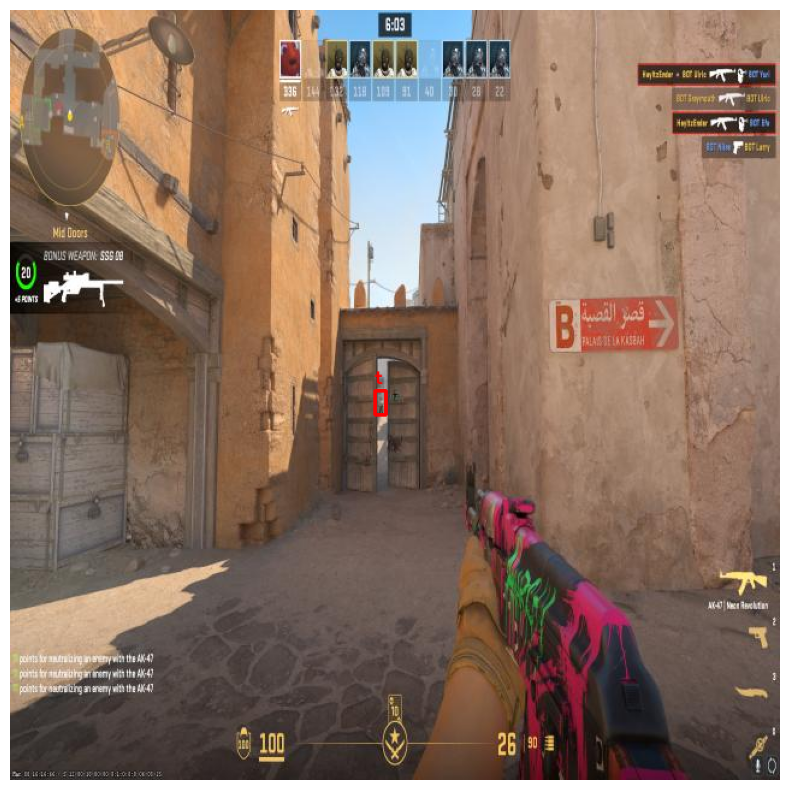

Mostrando muestra aleatoria: csdata_357_png.rf.1b66e094dc2bb1b9825fda2ee40b47cd.jpg


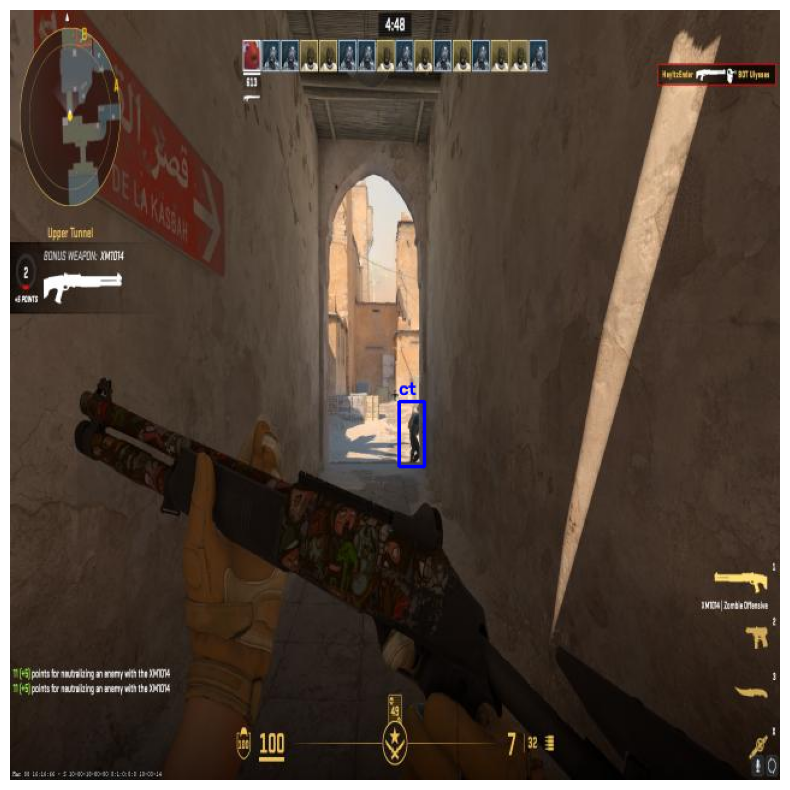

Mostrando muestra aleatoria: csdata_492_png.rf.95f91824475f672dcf6acf5cee1b3dde.jpg


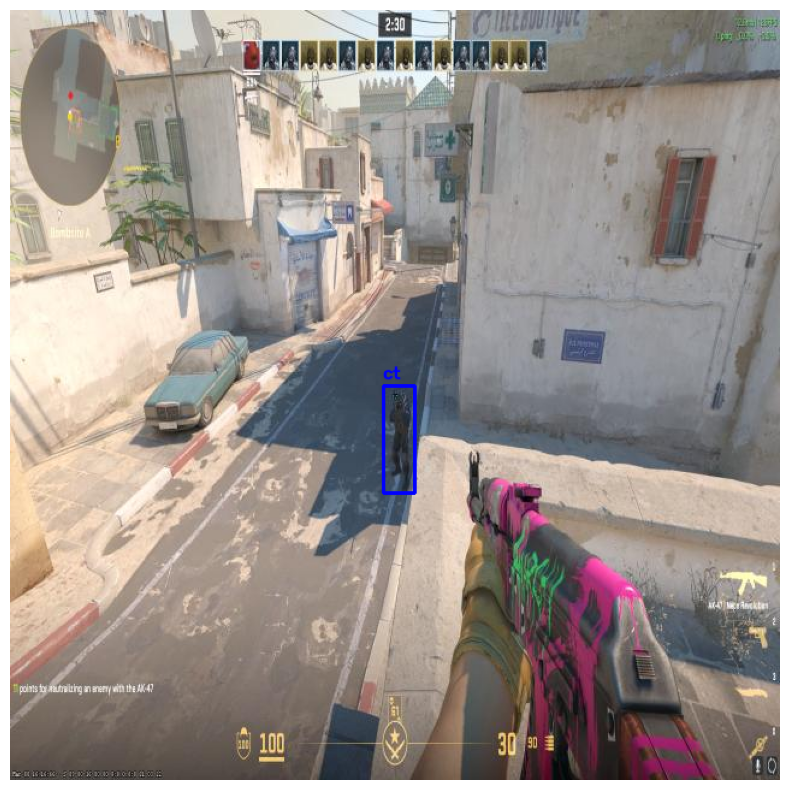

In [14]:
# Definición de rutas principales
images_dir = '/content/Counter-Strike-1/train/images'
labels_dir = '/content/Counter-Strike-1/train/labels'
class_names = dataset_info.get('names', ['ct', 't'])

# Ejecutar visualización de 3 imágenes al azar
plot_random_samples(images_dir, labels_dir, class_names, num_samples=3)